# Campaign finance

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'clean').is_dir())
output_dir = ROOT / 'output' / 'campaign_finance'
output_dir.mkdir(parents=True, exist_ok=True)
colors = ["#2864A6", "#C44747"]

# principal campaign committees
PRINCIPAL = {'C00916288': 'Brown', 'C00896019': 'Husted'}
r = pd.read_csv(ROOT / 'clean' / 'campaign_finance' / 'finance_reports_clean_v2.csv')
r = r[r.committee_id.isin(PRINCIPAL)].copy()
r['candidate'] = r.committee_id.map(PRINCIPAL)
r['receipts_less_contribution_refunds'] = r.total_receipts_period - r.total_contribution_refunds_period

In [2]:
# Q3 2026 (Jul 1 - Sep 30)
q3 = r[(r.coverage_start_date == '2026-07-01') & (r.coverage_end_date == '2026-09-30')]
q3.set_index('candidate')[['receipts_less_contribution_refunds', 'net_operating_expenditures_period',
                           'cash_on_hand_end_period', 'debts_owed_by_committee']]

,receipts_less_contribution_refunds,net_operating_expenditures_period,cash_on_hand_end_period,debts_owed_by_committee
candidate,,,,
Husted,4718137.01,5252461.08,8883293.28,0.0
Brown,22736238.26,34101093.21,4861451.93,0.0


In [3]:
# quarterly totals, 2026 Q1-Q3; Q2 = pre-primary (12P) + Q2 reports
y = r[(r.coverage_start_date >= '2026-01-01') & (r.coverage_end_date <= '2026-09-30')].copy()
y['quarter'] = 'Q' + ((pd.to_datetime(y.coverage_end_date).dt.month - 1) // 3 + 1).astype(str)
data = y.sort_values('coverage_end_date').groupby(['candidate', 'quarter']).agg(
    receipts_less_contribution_refunds=('receipts_less_contribution_refunds', 'sum'),
    net_operating_expenditures_period=('net_operating_expenditures_period', 'sum'),
    cash_on_hand_end_period=('cash_on_hand_end_period', 'last'))
data

receipts_less_contribution_refunds  \
candidate quarter                                       
Brown     Q1                              10069075.72   
          Q2                              13971357.69   
          Q3                              22736238.26   
Husted    Q1                               2859954.52   
          Q2                               3977889.76   
          Q3                               4718137.01   

                   net_operating_expenditures_period  cash_on_hand_end_period  
candidate quarter                                                              
Brown     Q1                              3452700.74              16514461.43  
          Q2                             14255658.85              16229741.32  
          Q3                             34101093.21               4861451.93  
Husted    Q1                               578551.73               8239954.70  
          Q2                              2791805.16               9418818.45  
          Q3                              5252461.08               8883293.28

In [4]:
# Jan-Sep 2026 totals, $ millions
(data.groupby('candidate')[['receipts_less_contribution_refunds', 'net_operating_expenditures_period']].sum() / 1e6).round(1)

,receipts_less_contribution_refunds,net_operating_expenditures_period
candidate,,
Brown,46.8,51.8
Husted,11.6,8.6


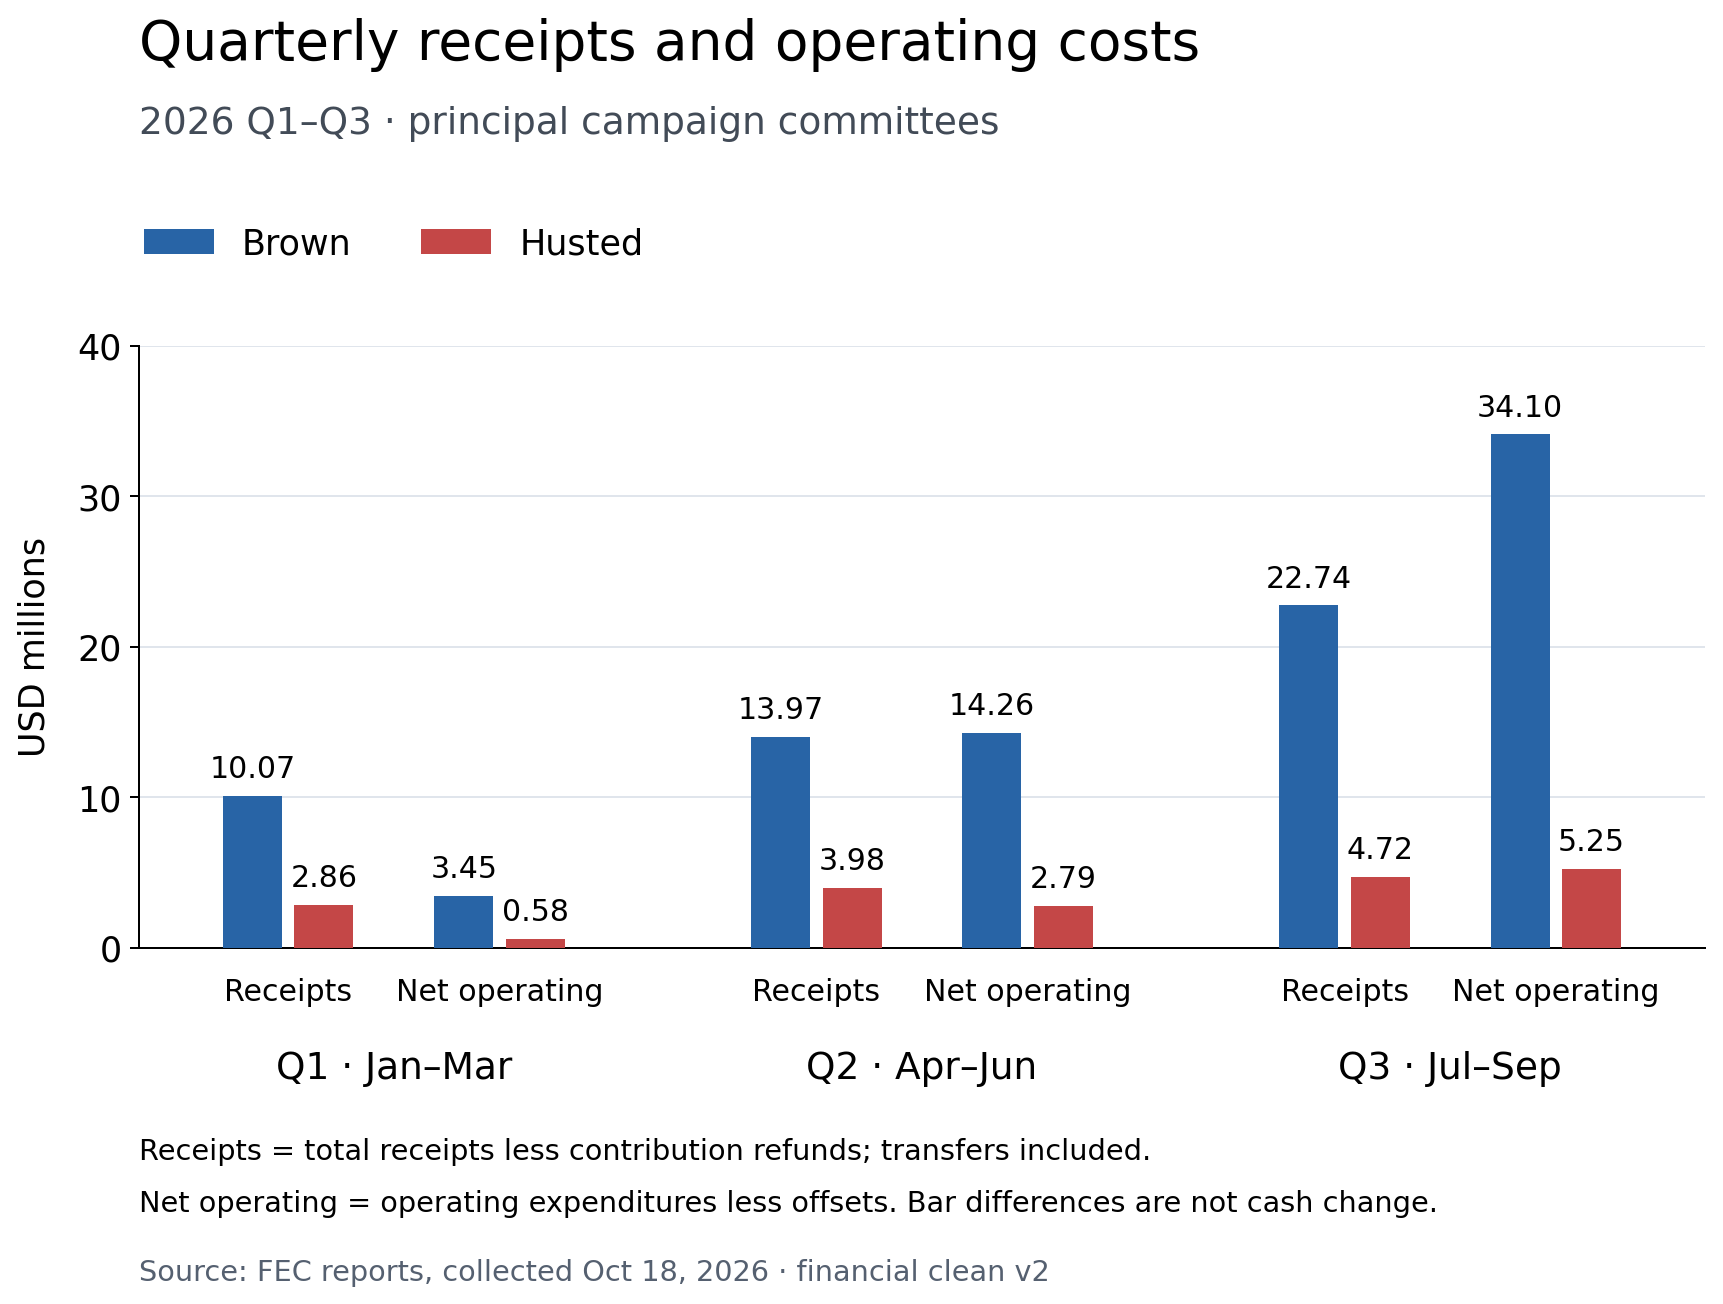

In [5]:
# AI was used to create this graph
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":14,"axes.spines.top":False,"axes.spines.right":False})
fig,ax=plt.subplots(figsize=(10,7.6),dpi=180)
fig.subplots_adjust(left=.11,right=.98,bottom=.29,top=.73)
fig.suptitle("Quarterly receipts and operating costs",fontsize=22,x=.11,y=.97,ha="left")
fig.text(.11,.885,"2026 Q1–Q3 · principal campaign committees",fontsize=15,color="#424B57")
centers=[0,1.7,3.4]
fields=["receipts_less_contribution_refunds","net_operating_expenditures_period"]
positions=[]
labels=[]
for q,center in zip(["Q1","Q2","Q3"],centers):
    for j,field in enumerate(fields):
        x=center+(-.34 if j==0 else .34)
        positions.append(x)
        labels.append("Receipts" if j==0 else "Net operating")
        for k,(name,color) in enumerate([("Brown","#2864A6"),("Husted","#C44747")]):
            value=data.loc[(name,q),field]/1e6
            assert value>=0
            bar=ax.bar(x+(k-.5)*.23,value,width=.19,color=color,zorder=3,label=name if q=="Q1" and j==0 else None)
            ax.bar_label(bar,labels=[f"{value:.2f}"],padding=5,fontsize=12)
for center,q,months in zip(centers,["Q1","Q2","Q3"],["Jan–Mar","Apr–Jun","Jul–Sep"]):
    ax.text(center,-.17,q+" · "+months,transform=ax.get_xaxis_transform(),ha="center",va="top",fontsize=15)
ax.set_xticks(positions,labels)
ax.tick_params(axis="x",length=0,pad=12,labelsize=12)
ax.set_xlim(-.82,4.22)
ax.set_ylim(0,40)
ax.set_yticks([0,10,20,30,40])
ax.set_ylabel("USD millions",labelpad=10)
ax.grid(axis="y",color="#E0E5EC",linewidth=.8,zorder=0)
fig.legend(*ax.get_legend_handles_labels(),loc="upper left",bbox_to_anchor=(.095,.84),ncol=2,frameon=False,fontsize=14)
fig.text(.11,.135,"Receipts = total receipts less contribution refunds; transfers included.",fontsize=11.5)
fig.text(.11,.097,"Net operating = operating expenditures less offsets. Bar differences are not cash change.",fontsize=11.5)
fig.text(.11,.047,"Source: FEC reports, collected Oct 18, 2026 · financial clean v2",fontsize=11.5,color="#556070")
fig.savefig(output_dir / "quarterly_receipts_and_costs_v1.png",dpi=180,facecolor="white")
plt.show()


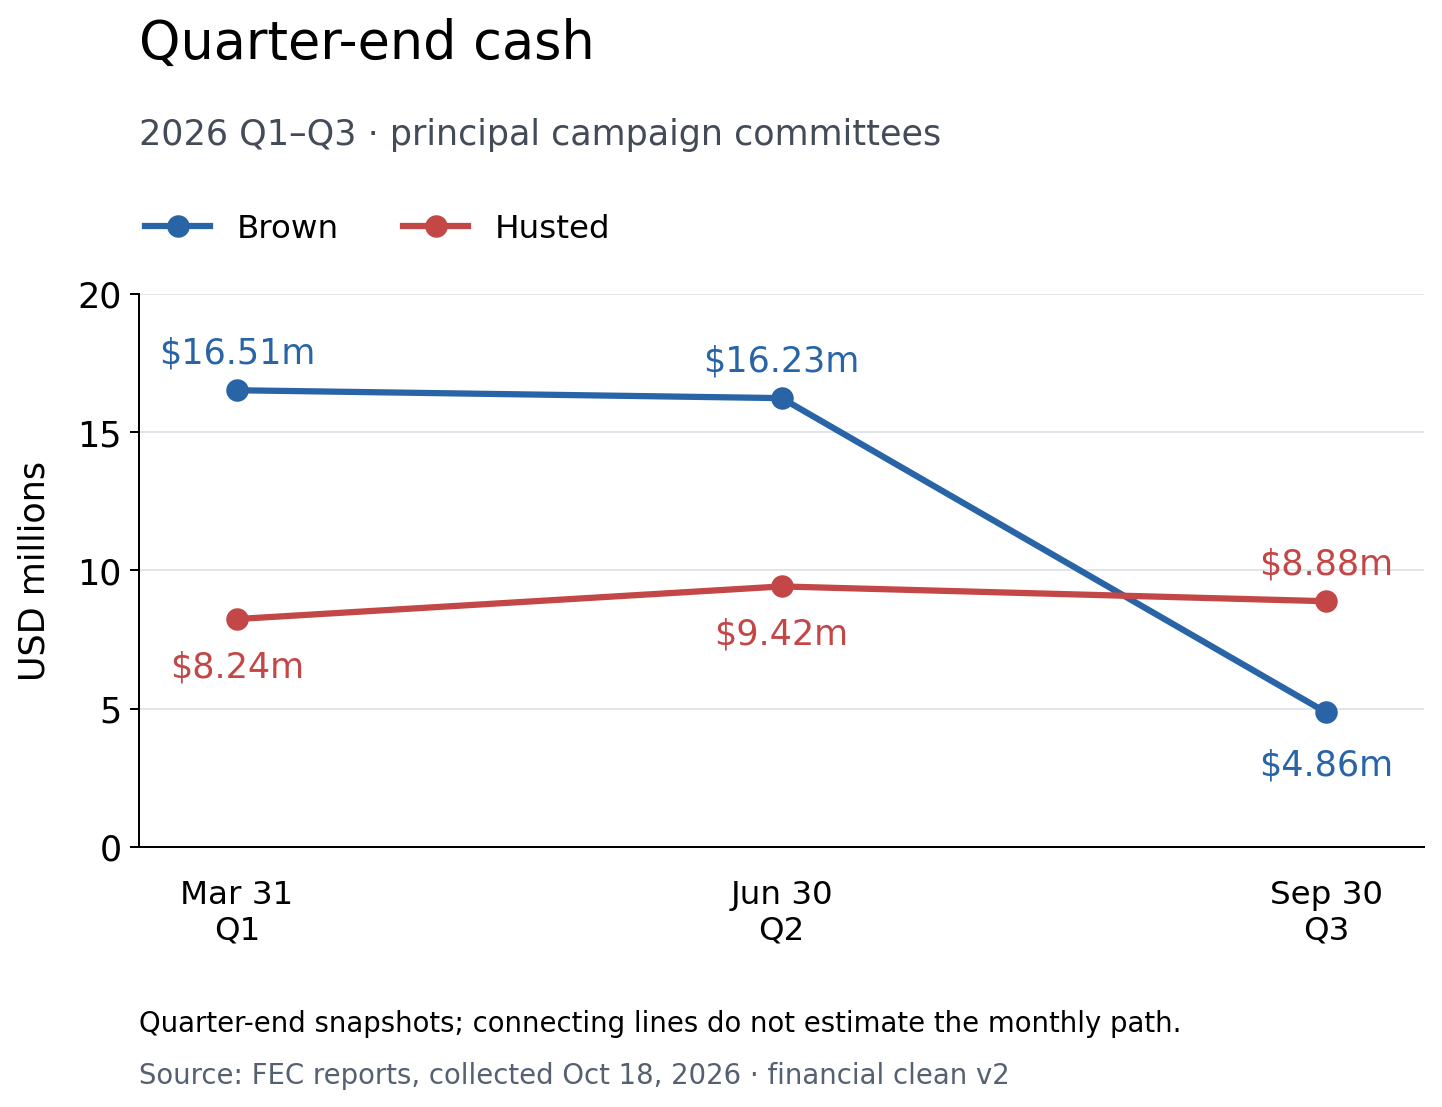

In [6]:
# AI was used to create this graph
fig, ax = plt.subplots(figsize=(8.5, 6.4), dpi=180)
fig.subplots_adjust(left=.13, right=.97, bottom=.25, top=.73)
fig.suptitle("Quarter-end cash", fontsize=21, x=.13, y=.97, ha="left")
fig.text(.13, .86, "2026 Q1–Q3 · principal campaign committees", fontsize=14, color="#424B57")
for index, label in enumerate(["Brown", "Husted"]):
    cash = [data.loc[(label, quarter), "cash_on_hand_end_period"] / 1e6 for quarter in ["Q1", "Q2", "Q3"]]
    ax.plot([0, 1, 2], cash, marker="o", markersize=8, linewidth=2.5,
            color=colors[index], label=label, zorder=3)
    for position, value in enumerate(cash):
        offset = (11 if position < 2 else -25) if index == 0 else (-23 if position < 2 else 11)
        ax.annotate(f"${value:.2f}m", (position, value), xytext=(0, offset),
                    textcoords="offset points", ha="center", fontsize=14, color=colors[index])
ax.set_xticks([0, 1, 2], ["Mar 31\nQ1", "Jun 30\nQ2", "Sep 30\nQ3"])
ax.set_xlim(-.18, 2.18)
ax.tick_params(axis="x", length=0, pad=13, labelsize=13)
ax.set_ylabel("USD millions", labelpad=10)
ax.set_ylim(0, 20)
ax.set_yticks([0, 5, 10, 15, 20])
ax.grid(axis="y", color="#E0E5EC", linewidth=.8, zorder=0)
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(.115, .825),
           ncol=2, frameon=False, fontsize=13)
fig.text(.13, .09, "Quarter-end snapshots; connecting lines do not estimate the monthly path.", fontsize=11)
fig.text(.13, .045, "Source: FEC reports, collected Oct 18, 2026 · financial clean v2", fontsize=11, color="#556070")
fig.savefig(output_dir / "cash_trend_2026_v1.png", dpi=180, facecolor="white")
plt.show()
